# GOL651 – 01 · NumPy, Pandas et Matplotlib
*GOL651 – 01 · NumPy, Pandas and Matplotlib*

**Objectifs.** Calculer avec des tableaux NumPy, analyser un fichier CSV avec Pandas et produire des graphiques avec Matplotlib.
Les données (`data/datasets/shipments.csv`) décrivent 40 expéditions fictives d'une entreprise de distribution au Québec.

*Goals: compute with NumPy arrays, analyse a CSV file with Pandas and plot with Matplotlib. The data describe 40 fictional shipments of a Québec distribution company.*

> Exécutez les cellules dans l'ordre avec **Maj + Entrée**. / *Run the cells in order with **Shift + Enter**.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
print("NumPy", np.__version__, "| Pandas", pd.__version__)

NumPy 2.5.4 | Pandas 3.0.6


In [2]:
from pathlib import Path

def find_project_root(start: Path = Path.cwd()) -> Path:
    """Folder that contains data/datasets (works inside Docker and on a laptop)."""
    for folder in [start, *start.parents]:
        if (folder / "data" / "datasets").is_dir():
            return folder
    raise FileNotFoundError("Project root not found: open this notebook from the course folder")

ROOT = find_project_root()
DATA = ROOT / "data"
print("Project folder:", ROOT)

Project folder: /workspace


## 1. NumPy : calcul vectoriel / *vectorized computation*

La **quantité économique de commande** (modèle de Wilson) minimise la somme des coûts de commande et de stockage :

$$Q^{*} = \sqrt{\frac{2\,D\,S}{H}}$$

où $D$ est la demande annuelle, $S$ le coût par commande et $H$ le coût de stockage annuel par unité.
NumPy applique la formule à **tous les produits à la fois**, sans boucle.

*The economic order quantity minimizes ordering + holding costs. NumPy evaluates it for all products at once, without a loop.*

In [3]:
products = np.array(["PAL-001", "GAN-080", "CAS-081", "ETQ-040"])
D = np.array([4_000, 6_000, 1_200, 2_500])      # annual demand (units)
S = np.array([45.0, 30.0, 30.0, 25.0])          # cost per order ($)
H = np.array([2.20, 0.80, 3.10, 1.10])          # holding cost ($/unit/year)

Q_star = np.sqrt(2 * D * S / H)                  # element-wise operations
orders_per_year = D / Q_star
total_cost = (D / Q_star) * S + (Q_star / 2) * H

for p, q, n, c in zip(products, Q_star, orders_per_year, total_cost):
    print(f"{p:<8} Q* = {q:7.1f} units   {n:5.1f} orders/year   cost {c:8.2f} $")

PAL-001  Q* =   404.5 units     9.9 orders/year   cost   889.94 $
GAN-080  Q* =   670.8 units     8.9 orders/year   cost   536.66 $
CAS-081  Q* =   152.4 units     7.9 orders/year   cost   472.44 $
ETQ-040  Q* =   337.1 units     7.4 orders/year   cost   370.81 $


## 2. Pandas : lire et explorer un CSV / *read and explore a CSV*

In [4]:
shipments = pd.read_csv(DATA / "datasets" / "shipments.csv", parse_dates=["ship_date"])
print(shipments.shape)
shipments.head()

(40, 8)


,shipment_id,ship_date,origin_city,destination_city,carrier,weight_kg,cost_cad,transit_days
0,SHP-0001,2026-01-11,Longueuil,Trois-Rivières,Transport Pelletier,576.9,258.72,3
1,SHP-0002,2026-01-17,Longueuil,Montréal,Day & Ross,627.0,282.75,3
2,SHP-0003,2026-01-24,Montréal,Longueuil,Day & Ross,229.6,118.35,1
3,SHP-0004,2026-01-31,Longueuil,Québec,Postes Canada,147.1,102.84,1
4,SHP-0005,2026-02-06,Longueuil,Sherbrooke,Transport Pelletier,811.9,387.97,3


In [5]:
shipments.describe(include="number").round(2)

,weight_kg,cost_cad,transit_days
count,40.00,40.00,40.00
mean,498.58,237.65,2.33
std,297.58,125.73,1.12
min,33.20,34.32,1.00
25%,229.05,119.00,1.00
50%,561.05,260.42,2.00
75%,771.32,342.78,3.00
max,948.70,445.23,4.00


### Agrégations / *aggregations*
Coût moyen et poids total par transporteur, puis tableau croisé destination × transporteur.

*Average cost and total weight per carrier, then a destination × carrier pivot table.*

In [6]:
by_carrier = (
    shipments.groupby("carrier")
    .agg(shipments=("shipment_id", "count"),
         total_weight_kg=("weight_kg", "sum"),
         avg_cost_cad=("cost_cad", "mean"))
    .round(1)
    .sort_values("avg_cost_cad")
)
by_carrier

,shipments,total_weight_kg,avg_cost_cad
carrier,,,
Day & Ross,11,4891.7,214.7
Postes Canada,13,6172.2,225.8
Purolator,5,2550.6,242.9
Transport Pelletier,11,6328.6,272.3


In [7]:
pd.pivot_table(shipments, index="destination_city", columns="carrier",
               values="cost_cad", aggfunc="sum", fill_value=0).round(0)

carrier,Day & Ross,Postes Canada,Purolator,Transport Pelletier
destination_city,,,,
Brossard,38.0,277.0,709.0,0.0
Gatineau,422.0,250.0,0.0,952.0
Laval,299.0,0.0,0.0,200.0
Longueuil,228.0,389.0,0.0,0.0
Montréal,283.0,319.0,0.0,37.0
Québec,140.0,103.0,279.0,416.0
Sherbrooke,707.0,485.0,227.0,388.0
Trois-Rivières,244.0,1113.0,0.0,1001.0


## 3. Régression linéaire simple avec NumPy / *simple linear regression*

On estime le coût d'une expédition en fonction de son poids : $\hat{c} = \beta_0 + \beta_1\,w$.

*We estimate the cost of a shipment from its weight.*

In [8]:
beta1, beta0 = np.polyfit(shipments["weight_kg"], shipments["cost_cad"], deg=1)
r = np.corrcoef(shipments["weight_kg"], shipments["cost_cad"])[0, 1]
print(f"cost ≈ {beta0:.2f} + {beta1:.4f} × weight   (R² = {r**2:.3f})")

cost ≈ 28.08 + 0.4203 × weight   (R² = 0.990)


## 4. Matplotlib : graphiques / *charts*

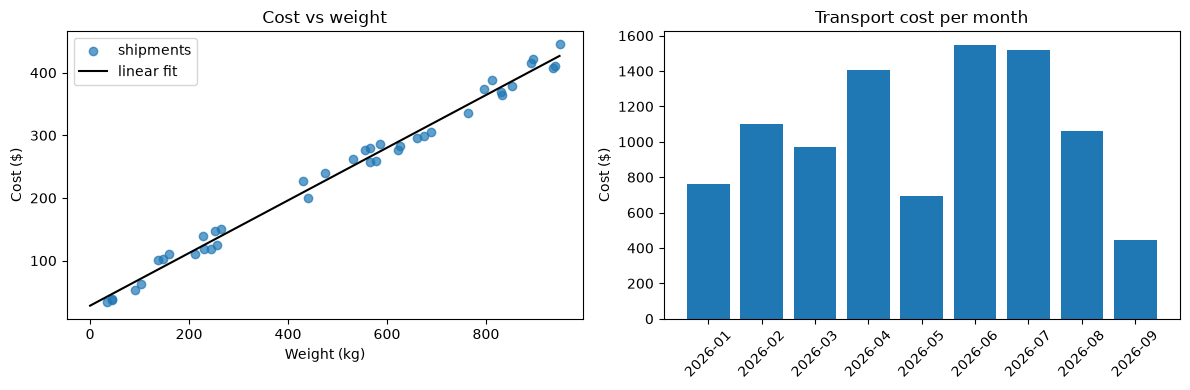

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.scatter(shipments["weight_kg"], shipments["cost_cad"], alpha=0.7, label="shipments")
w = np.linspace(0, shipments["weight_kg"].max(), 50)
ax1.plot(w, beta0 + beta1 * w, color="black", label="linear fit")
ax1.set(title="Cost vs weight", xlabel="Weight (kg)", ylabel="Cost ($)")
ax1.legend()

monthly = shipments.set_index("ship_date")["cost_cad"].resample("MS").sum()
ax2.bar(monthly.index.strftime("%Y-%m"), monthly.values)
ax2.set(title="Transport cost per month", ylabel="Cost ($)")
ax2.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

### À vous / *Your turn*
1. Quel transporteur a le meilleur coût par kilogramme ? / *Which carrier has the best cost per kilogram?*
2. Refaites la régression pour un seul transporteur. / *Redo the regression for a single carrier.*